# Meridional Overturning Circulation

This recipe shows an example of calculating the global meridional overturning circulation in density--latitude space using output from `MOM6`. South of 65$^\circ$N we sum the meridional transport along the rows of the model grid. North of 65$^\circ$N the rows of the model's tripolar grid no longer follow latitude circles, so there we use [`sectionate`](https://sectionate.readthedocs.io) to compute the transport across true latitude circles. We also discuss the overturning in depth--latitude space, and plot separate basin overturning streamfunctions.

**Requirements:** The `conda/analysis3-26.10` (or later) module on ARE, and `sectionate` 0.3.5 or later, which the recipe installs below if needed. Earlier versions of `sectionate` get the transports wrong north of 65$^\circ$N, where every latitude circle crosses the fold of the tripolar grid; north of about 80$^\circ$N the errors reach several tenths of a Sverdrup. Add `gdata/vk83` to the storage of your ARE session: we read the model's horizontal grid file from there. We recommend an ARE session with more than 14 cores to make these computations. Ideally, use a whole Gadi compute node from `normalbw`, i.e., 28 cores.

## Information needed to adapt to MOM5:

Diagnostics needed:

* `ty_trans_rho`: meridional transport binned online into `rho2` layers. This is on the same grid as `vmo`, i.e. the centre of the northern tracer cell's face.
* `tx_trans_rho`: zonal transport binned online into `rho2` layers, on the same grid as `umo`, i.e. the centre of the eastern tracer cell's face. We need it north of 65$^\circ$N, where the transport across a latitude circle also goes through the east and west faces of the grid cells.
* `pot_rho_2`: potential density referenced to 2000 metres needed to remapping the overturning to depth coordinates.

**Notes**

For low-resolution `MOM5`-based runs that include mesoscale eddy flux parameterisations, we need to explicitly include the volume transport from the Gent-McWilliams eddy parameterisation (`ty_trans_rho_gm`). This transport is already cumulatively summed in the vertical (see section 32.3.1 of the [MOM5 manual](https://mom-ocean.github.io/assets/pdfs/MOM5_manual.pdf)), so it needs to be added _after_ the cumulative sum of `ty_trans_rho` when calculating the overturning streamfuncton `psi` (see [this example](https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/overturning_circulation/GlobalOverturningStreamfunction.ipynb)). For `MOM6` we don't need to worry about this, because it is already included in `vmo`. Similarly, all resolutions in ACCESS-OM2 `MOM5` have parameterised submesoscale meridional transport (`ty_trans_submeso`) which is already cumulatively summed in the vertical and not included in `ty_trans_rho`. However, it tends to be relatively unimportant for the deep circulation, which is where we are primarily interested, so we are probably can safely ignore it. Again, for `MOM6`, this is conveniently already included in the `vmo` output.

MOM5 saves its output on a *non-symmetric* grid, i.e., with one face less in each direction than MOM6's *symmetric* output used here. `sectionate` (0.3.5 or later) works with non-symmetric grids too: when building the `xgcm.Grid` below, put the corner coordinates `xu_ocean` and `yu_ocean` at the `right` position instead of `outer`.

## MOM6 Recipe:

We need `sectionate` 0.3.5 or later. Until the `conda/analysis3` environment includes it, the next cell installs it in your home directory and puts it first on Python's search path. It needs internet access only the first time. If `pip` can't reach the internet from your ARE session, run
```
pip install --no-deps --target ~/sectionate-0.3.5 sectionate==0.3.5
```
once in a terminal on a Gadi login node, with the `conda/analysis3` module loaded, and then run the cell.

In [1]:
import os
import sys

sectionate_dir = os.path.expanduser("~/sectionate-0.3.5")
if not os.path.isdir(sectionate_dir):
    %pip install --quiet --no-deps --target {sectionate_dir} sectionate==0.3.5
sys.path.insert(0, sectionate_dir)

In [2]:
import numpy as np
import xarray as xr

from dask.distributed import Client

import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft

import xgcm
import sectionate

import intake
cat = intake.cat.access_nri

print(f"sectionate version {sectionate.__version__}")

sectionate version 0.3.5


In [3]:
client = Client(threads_per_worker = 1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 28
Total threads: 28,Total memory: 112.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:37359,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:43387,Total threads: 1
Dashboard: http://127.0.0.1:42451/status,Memory: 4.00 GiB
Nanny: tcp://127.0.0.1:33323,


For this example, we are using 1 year of a 25 km ACCESS-OM3 IAF simulation. If you want to increase the resolution or integrate over a longer time you might need a bigger ARE session. 

**Note**: We are using this experiment because it is currently to only global MOM6 output with the necessary output.

First we load up `vmo` and sum in the zonal direction.

Most ACCESS-OM2 and MOM6 simulations output mass transport (with units of kg/s), so we convert to volume transport, i.e., to Sverdrup (Sv = 10$^6$ m$^3$/s).

In [4]:
experiment = "MC_25km_jra_iaf+wombatlite-test3v2-00532b88"
start_time = "1990-01-01"
end_time = "1990-12-31"

# Because this is only a test simulation, not permanent data, it is not in the main ACCESS-NRI 
# intake catalog, so we need to give instructions for where to find the relevant intake catalog:
OM3_datastore = intake.open_esm_datastore(
    "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json", 
    columns_with_iterables=[
            "variable",
            "variable_long_name",
            "variable_standard_name",
            "variable_cell_methods",
            "variable_units",
    ] # This is important
)

# We need to specify "file_id" here, because there is "vmo" saved both on depth and density coordinates. 
# ".*" here is wildcard to ensure that the filenames contain "rho2_l", i.e., the density coordinate name.
df = OM3_datastore.search(variable="vmo", frequency="1mon", file_id=".*rho2_l.*")
vmo = df.to_dask(xarray_open_kwargs={"decode_timedelta": True}).vmo
vmo = vmo.sel(time=slice(start_time, end_time))

# We will also need the zonal transport, umo, north of 65°N (see below):
umo = OM3_datastore.search(variable="umo", frequency="1mon", file_id=".*rho2_l.*")
umo = umo.to_dask(xarray_open_kwargs={"decode_timedelta": True}).umo
umo = umo.sel(time=slice(start_time, end_time))

# convert mass transport -> volume transport and then convert units -> Sv
rho0 = 1035 # kg/m^3, average seawater density
psi = (vmo / rho0) / 1e6
psi.attrs["units"] = "Sv"

# sum in longitude:
psi_sum_lon = psi.sum("xh")

# Cumulatively sum the transport in the vertical, time average and load.
# Note that we want to sum from the bottom up, but .cumsum sums from the top down,
# which is why we substract the sum in the second term here:
psi_avg = psi_sum_lon.cumsum("rho2_l") - psi_sum_lon.sum("rho2_l")
psi_avg = psi_avg.mean("time")
psi_avg = psi_avg.load()

# Plotting in density coordinates

Now we are ready to plot. We usually plot the streamfunction over a reduced range of density levels to highlight the deep ocean contribution.

In [5]:
def levels_and_colorbarticks(max_value):
    """ Return the levels and the colorbarticks for the streamfunction plot.
    It may seem complicated but the truth is we just want to avoid the 0 contour
    so that the plot looks soothing to the eye. 
    Note this function can result in mismatched contour levels and ticks if you 
    change max_psi below to be an even number. """

    levels = np.hstack((np.arange(-max_value, 0, 2), np.flip(-np.arange(-max_value, 0, 2))))
    cbarticks = np.hstack((np.flip(-np.arange(3, max_value, 6)), np.arange(3, max_value, 6)))

    return levels, cbarticks

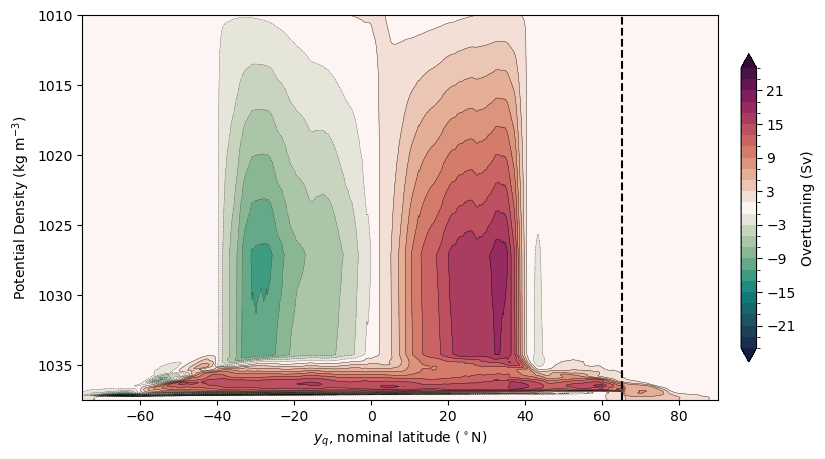

In [6]:
plt.figure(figsize=(10, 5))

# Best if this is an odd number - otherwise levels and cbarticks may be mismatched:
max_psi = 25 # Sv

levels, cbarticks = levels_and_colorbarticks(max_psi)

psi_avg.plot.contourf(levels=levels,
                      cmap=cm.cm.curl,
                      extend='both',
                      cbar_kwargs={
                          'shrink': 0.8, 
                          'label': 'Overturning (Sv)', 
                          'ticks': cbarticks,
                          'pad': 0.03,
                      })

psi_avg.plot.contour(levels=levels,
                     colors='k',
                     linewidths=0.25)

plt.gca().invert_yaxis()

plt.ylim((1037.5, 1010))
plt.ylabel('Potential Density (kg m$^{-3}$)')
plt.xlabel('$y_q$, nominal latitude ($^\circ$N)')
plt.axvline(65, color='k', linestyle='--')
plt.xlim([-75, 90]);

North of 65$^\circ$N (dashed line) this plot is not what it seems: there, the $x$-axis is not latitude. The next sections explain why, and how to fix it.

# North of 65°N: the grid rows are not latitude circles

Above, we summed `vmo` along `xh`, that is, along a row of the model grid with constant `yq`, and plotted the result against `yq`. That is the transport across a latitude circle only if the grid row lies along one.

ACCESS-OM3, like ACCESS-OM2 and most global ocean models, uses a *tripolar* grid. South of 65$^\circ$N it is a regular latitude--longitude (Mercator) grid, so each row does lie along a latitude circle. North of 65$^\circ$N the grid is bent so that, instead of a single pole at the North Pole, it has two poles that sit on land, in Canada and in Siberia; this avoids the singularity at the North Pole. There, `xh` and `yq` are just labels: a grid row no longer follows a latitude circle, and `vmo`, the transport through the northern faces of the cells, is no longer northward.

To see this, we need the true longitude and latitude of the grid. The model's `static` file has them, as `geolon`, `geolat` (cell centres) and `geolon_c`, `geolat_c` (cell corners), but in this run they are missing (`NaN`) over parts of the land: MOM6 doesn't compute anything on processor tiles that are entirely land. So we take them from the model's horizontal grid file, `ocean_hgrid.nc` (listed in the run's `config.yaml`). This is a *supergrid* with twice the model's resolution: every other point is a cell corner, and the points in between are the cell centres and the centres of the cell faces, where the model's `u` and `v` (and `umo` and `vmo`) live.

In [7]:
hgrid = xr.open_dataset("/g/data/vk83/configurations/inputs/access-om3/mom/grids/mosaic/global.25km/2025.09.02/ocean_hgrid.nc")

x, y = hgrid.x.values, hgrid.y.values

grid_coords = xr.Dataset(
    coords={
        "xh": vmo.xh, "yh": umo.yh, "xq": umo.xq, "yq": vmo.yq,
        "geolon_c": (("yq", "xq"), x[::2, ::2]),    # cell corners
        "geolat_c": (("yq", "xq"), y[::2, ::2]),
        "geolon":   (("yh", "xh"), x[1::2, 1::2]),  # cell centres
        "geolat":   (("yh", "xh"), y[1::2, 1::2]),
        "geolon_u": (("yh", "xq"), x[1::2, ::2]),   # centres of the east/west faces, where umo lives
        "geolat_u": (("yh", "xq"), y[1::2, ::2]),
        "geolon_v": (("yq", "xh"), x[::2, 1::2]),   # centres of the north/south faces, where vmo lives
        "geolat_v": (("yq", "xh"), y[::2, 1::2]),
    }
)
grid_coords

<xarray.Dataset> Size: 106MB
Dimensions:   (xh: 1440, yh: 1152, xq: 1441, yq: 1153)
Coordinates:
  * xh        (xh) float64 12kB -279.9 -279.6 -279.4 ... 79.38 79.62 79.88
    geolon    (yh, xh) float64 13MB -279.9 -279.6 -279.4 ... 80.0 80.0 80.0
    geolat    (yh, xh) float64 13MB -81.58 -81.58 -81.58 ... 65.26 65.16 65.05
    geolon_v  (yq, xh) float64 13MB -279.9 -279.6 -279.4 ... 80.0 80.0 80.0
    geolat_v  (yq, xh) float64 13MB -81.62 -81.62 -81.62 ... 65.26 65.16 65.05
  * yh        (yh) float64 9kB -81.58 -81.52 -81.45 -81.39 ... 89.74 89.84 89.95
  * xq        (xq) float64 12kB -280.0 -279.8 -279.5 -279.2 ... 79.5 79.75 80.0
    geolon_c  (yq, xq) float64 13MB -280.0 -279.8 -279.5 ... 80.0 80.0 80.0
    geolat_c  (yq, xq) float64 13MB -81.62 -81.62 -81.62 ... 65.21 65.11 65.0
    geolon_u  (yh, xq) float64 13MB -280.0 -279.8 -279.5 ... 80.0 80.0 80.0
    geolat_u  (yh, xq) float64 13MB -81.58 -81.58 -81.58 ... 65.21 65.11 65.0
  * yq        (yq) float64 9kB -81.62 -81.55 -81.49 -81.42 ... 89.79 89.9 90.0
Data variables:
    *empty*

Let's look at the true latitude along a few rows of cell corners:

In [8]:
for row in [55, 60, 65, 70, 75, 80, 85]:
    geolat_row = grid_coords.geolat_c.sel(yq=row, method="nearest")
    print(f"row yq = {float(geolat_row.yq):6.2f}: true latitude from {float(geolat_row.min()):6.2f} to {float(geolat_row.max()):6.2f} °N")

row yq =  55.00: true latitude from  55.00 to  55.00 °N
row yq =  59.96: true latitude from  59.96 to  59.96 °N
row yq =  65.00: true latitude from  65.00 to  65.00 °N
row yq =  70.00: true latitude from  65.00 to  70.00 °N
row yq =  75.00: true latitude from  65.00 to  75.00 °N
row yq =  80.00: true latitude from  65.00 to  80.00 °N
row yq =  85.00: true latitude from  65.00 to  85.00 °N


Up to 65$^\circ$N each row lies on a latitude circle. Further north, every row starts at 65$^\circ$N, at the grid's poles over land, and reaches the latitude given by `yq` only halfway between them. On a map:

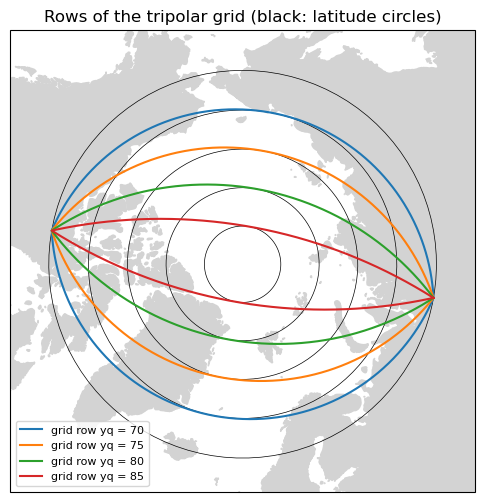

In [9]:
def arctic_map(ax):
    ax.set_extent([-180, 180, 60, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cft.LAND, color='lightgrey')
    ax.gridlines(ylocs=[65, 70, 75, 80, 85], xlocs=[], color='k', linewidth=0.5)

fig = plt.figure(figsize=(6, 6))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
arctic_map(ax)
for k, row in enumerate([70, 75, 80, 85]):
    row_coords = grid_coords.sel(yq=row, method="nearest")
    ax.plot(row_coords.geolon_c, row_coords.geolat_c, color=f'C{k}', transform=ccrs.Geodetic(),
            label=f'grid row yq = {float(row_coords.yq):.0f}')
ax.legend(loc='lower left', fontsize=8)
ax.set_title('Rows of the tripolar grid (black: latitude circles)');

So north of 65$^\circ$N, summing `vmo` along `xh` gives the transport across a grid row, which is a closed curve around the Arctic, but not the latitude circle we label it with.

# Transport across latitude circles with `sectionate`

What we want north of 65$^\circ$N is the transport across a latitude circle, e.g., 75$^\circ$N. On the model grid, the best we can do is a closed path along the edges of the grid cells that follows the latitude circle as closely as possible, as a staircase. The transport across that path is the sum, over the cell faces that make up the staircase, of the transport through each face: `umo` for the east and west faces and `vmo` for the north and south faces, each with a sign that says whether the flow goes into or out of the region north of the path.

Note that we don't need to rotate any velocity vectors to the north: the model's `umo` and `vmo` are already the transports through the cell faces, and the transport across a closed path is just the sum of the transports through the faces along it.

[`sectionate`](https://sectionate.readthedocs.io) does exactly this. `sectionate.grid_section` finds the staircase of cell corners that best follows a path through given points, and `sectionate.convergent_transport` sums the transport through the faces along it. It needs an `xgcm.Grid` that describes the model grid: here, a symmetric C-grid (`xq` and `yq` have one more point than `xh` and `yh`), periodic in the zonal direction, and with the true coordinates of the corners, the centres and the faces.

Two things make the computation cheaper:
* The overturning is linear in the transport, so we can average the transport over time first.
* `sectionate` searches the whole grid for the grid points nearest to the section, so we only give it the grid north of 60$^\circ$N, which is all we need for sections north of 65$^\circ$N.

In [10]:
j60 = int(np.argmin(np.abs(vmo.yq.values - 60)))   # the first row of corners we keep
north_of_60 = {"yh": slice(j60, None), "yq": slice(j60, None)}

transports = xr.Dataset({
    "umo": umo.mean("time").isel(yh=north_of_60["yh"]),
    "vmo": vmo.mean("time").isel(yq=north_of_60["yq"]),
}).fillna(0).load()
transports = transports.assign_coords(grid_coords.isel(north_of_60).coords)

grid = xgcm.Grid(
    transports,
    coords={"X": {"center": "xh", "outer": "xq"},
            "Y": {"center": "yh", "outer": "yq"}},
    boundary={"X": "periodic", "Y": "extend"},
    autoparse_metadata=False,
)
grid

<xgcm.Grid>
X Axis (periodic, boundary='periodic'):
  * center   xh --> outer
  * outer    xq --> center
Y Axis (not periodic, boundary='extend'):
  * center   yh --> outer
  * outer    yq --> center

To follow a latitude circle, we give `sectionate` points along it every 5$^\circ$ of longitude. `sectionate` joins consecutive points with great circles, so the points must be close enough together for those to stay close to the latitude circle. `topology="MOM-tripolar"` tells it how the rows of the grid connect across the top of the tripolar grid.

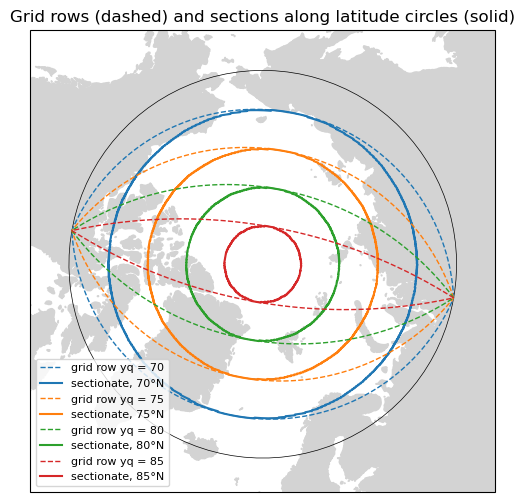

In [11]:
def section_along_latitude(lat, dlon=5):
    """Staircase of cell corners that follows the latitude circle `lat`."""
    lons = np.arange(0, 360 + dlon, dlon)
    lats = np.full(lons.shape, lat, dtype=float)
    i_c, j_c, lons_c, lats_c = sectionate.grid_section(grid, lons, lats, topology="MOM-tripolar")
    return i_c, j_c, lons_c, lats_c

fig = plt.figure(figsize=(6, 6))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
arctic_map(ax)
for k, lat in enumerate([70, 75, 80, 85]):
    row_coords = grid_coords.sel(yq=lat, method="nearest")
    ax.plot(row_coords.geolon_c, row_coords.geolat_c, color=f'C{k}', linestyle='--', linewidth=1,
            transform=ccrs.Geodetic(), label=f'grid row yq = {float(row_coords.yq):.0f}')
    i_c, j_c, lons_c, lats_c = section_along_latitude(lat)
    ax.plot(lons_c, lats_c, color=f'C{k}', transform=ccrs.Geodetic(), label=f'sectionate, {lat}°N')
ax.legend(loc='lower left', fontsize=8)
ax.set_title('Grid rows (dashed) and sections along latitude circles (solid)');

Now the transport across a section. `convergent_transport` returns, for each face along the section, the transport through it with a sign: by default, positive into the region enclosed by the section, which for our eastward sections around the globe is the region *south* of the section. So the northward transport is minus its sum along the section.

In [12]:
def northward_transport(lat):
    """Northward transport (kg/s) in each density layer across the latitude circle `lat`."""
    i_c, j_c, _, _ = section_along_latitude(lat)
    transport = sectionate.convergent_transport(grid, i_c, j_c, utr="umo", vtr="vmo",
                                                layer=None, interface=None)
    return -transport.conv_mass_transport.sum("sect")

As a check, south of 65$^\circ$N, where the grid rows are latitude circles, the section along a row should give the same overturning as summing `vmo` along that row:

In [13]:
row = vmo.yq.sel(yq=62, method="nearest")
psi_row_sectionate = northward_transport(float(row)) / rho0 / 1e6
psi_row_sectionate = psi_row_sectionate.cumsum("rho2_l") - psi_row_sectionate.sum("rho2_l")

difference = np.abs(psi_row_sectionate - psi_avg.sel(yq=row)).max()
print(f"row yq = {float(row):.2f}: largest difference between the two: {float(difference):.1e} Sv")

row yq = 62.02: largest difference between the two: 1.3e-06 Sv


They agree to round-off. Now we compute the overturning across latitude circles north of 65$^\circ$N, every 0.5$^\circ$ up to 89.5$^\circ$N. This takes about 12 minutes, almost all of it in `grid_section`.

In [14]:
%%time
lats_north = np.arange(65.5, 89.51, 0.5)

transport_north = xr.concat([northward_transport(lat) for lat in lats_north],
                            dim=xr.DataArray(lats_north, dims="lat", name="lat"))

psi_north = transport_north / rho0 / 1e6
psi_north = psi_north.cumsum("rho2_l") - psi_north.sum("rho2_l")
psi_north = psi_north.transpose("rho2_l", "lat").load()

CPU times: user 11min 20s, sys: 5min 4s, total: 16min 25s
Wall time: 11min 36s


### Checking the transports

There is an independent way to get the net transport across a latitude circle, which makes a good check. Whatever flows across the circle into the polar cap north of it flows into the grid cells of the cap. If we add up the horizontal convergence of `umo` and `vmo` over all the cells whose centres lie north of the circle, the flow through every face shared by two of these cells cancels, and only the flow across the boundary of the cap remains (this is the divergence theorem). That boundary is also a staircase that follows the latitude circle, though not exactly the same one as `sectionate`'s.

Summed over all density layers, the transport into the cap should be small: it can only change the volume of the cap or balance the freshwater flux through its surface.

In [15]:
# Depth-integrated transports; float64 avoids round-off in the sums over many cells.
u = transports.umo.sum("rho2_l").values.astype("float64")
v = transports.vmo.sum("rho2_l").values.astype("float64")

# On the symmetric grid, u[:, i] is on the west face of cell i and u[:, i+1] on its east face;
# v[j, :] is on the south face of the cells in row j and v[j+1, :] on their north face.
convergence = (u[:, :-1] - u[:, 1:]) + (v[:-1, :] - v[1:, :])
geolat = transports.geolat.values

print("latitude   northward transport (Sv)")
print("           convergence   sectionate")
for lat in [70, 75, 80, 82.5, 85, 87.5, 89]:
    from_convergence = convergence[geolat > lat].sum() / rho0 / 1e6
    from_sectionate = float(northward_transport(lat).sum("rho2_l")) / rho0 / 1e6
    print(f"{lat:6.1f}       {from_convergence:+7.3f}      {from_sectionate:+7.3f}")

latitude   northward transport (Sv)
           convergence   sectionate


  70.0        -0.162       -0.161


  75.0        -0.037       -0.037


  80.0        +0.002       +0.002


  82.5        +0.013       +0.013


  85.0        +0.007       +0.007


  87.5        +0.003       +0.003


  89.0        +0.001       +0.001


The two agree to within 0.001 Sv at every latitude, all the way to the pole; the small differences come from the slightly different staircases. North of about 80$^\circ$N the latitude circles cross the line along which the tripolar grid folds onto itself, so this also checks that `sectionate` joins the two sides of the fold correctly.

(Summing the convergence over the cells north of each latitude, layer by layer, is itself another way to compute the overturning across latitude circles; the [`regionate`](https://github.com/hdrake/regionate) package builds on this idea.)

### The overturning against true latitude

We now combine the zonal sums along the grid rows south of 65$^\circ$N, which are exact there, with the `sectionate` overturning north of 65$^\circ$N:

In [16]:
psi_lat = xr.concat([psi_avg.sel(yq=slice(None, 65)).rename(yq="lat"), psi_north], dim="lat")
psi_lat.lat.attrs = {"long_name": "latitude", "units": "degrees_north"}
psi_lat.attrs["units"] = "Sv"

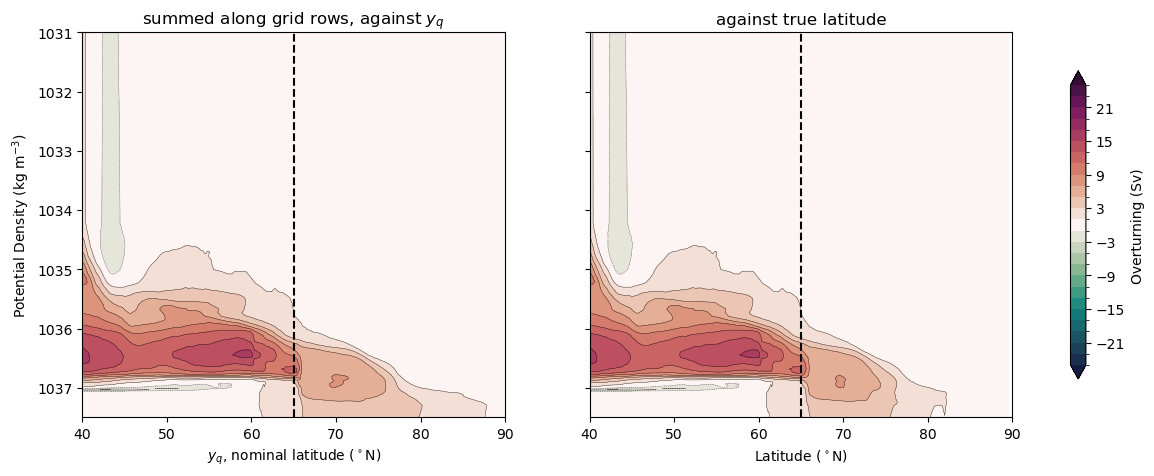

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

max_psi = 25 # Sv
levels, cbarticks = levels_and_colorbarticks(max_psi)

for ax, data, title in zip(axs, [psi_avg.sel(yq=slice(40, None)), psi_lat.sel(lat=slice(40, None))],
                           ['summed along grid rows, against $y_q$', 'against true latitude']):
    h = data.plot.contourf(ax=ax, levels=levels, cmap=cm.cm.curl, extend='both', add_colorbar=False)
    data.plot.contour(ax=ax, levels=levels, colors='k', linewidths=0.25)
    ax.axvline(65, color='k', linestyle='--')
    ax.set_xlim([40, 90])
    ax.set_title(title)

axs[0].set_xlabel('$y_q$, nominal latitude ($^\\circ$N)')
axs[1].set_xlabel('Latitude ($^\\circ$N)')
axs[0].set_ylim((1037.5, 1031))
axs[0].set_ylabel('Potential Density (kg m$^{-3}$)')
axs[1].set_ylabel('')
fig.colorbar(h, ax=axs, shrink=0.8, label='Overturning (Sv)', ticks=cbarticks);

The two agree south of 65$^\circ$N and differ north of it. A grid row reaches its nominal latitude $y_q$ only in the middle of the Arctic and dips to 65$^\circ$N at the grid's poles, so the left panel places the overturning at nominal latitudes further north than the latitude circles it actually crosses.

Here is the whole overturning against true latitude:

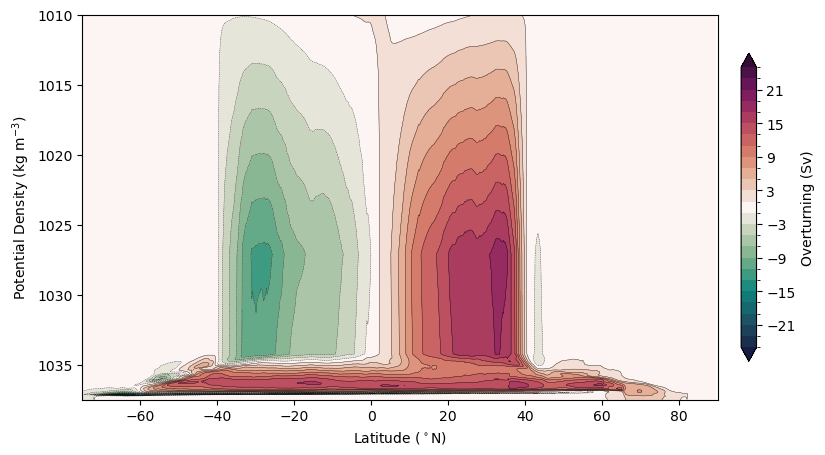

In [18]:
plt.figure(figsize=(10, 5))

max_psi = 25 # Sv
levels, cbarticks = levels_and_colorbarticks(max_psi)

psi_lat.plot.contourf(levels=levels,
                      cmap=cm.cm.curl,
                      extend='both',
                      cbar_kwargs={
                          'shrink': 0.8,
                          'label': 'Overturning (Sv)',
                          'ticks': cbarticks,
                          'pad': 0.03,
                      })

psi_lat.plot.contour(levels=levels,
                     colors='k',
                     linewidths=0.25)

plt.gca().invert_yaxis()

plt.ylim((1037.5, 1010))
plt.ylabel('Potential Density (kg m$^{-3}$)')
plt.xlabel('Latitude ($^\\circ$N)')
plt.xlim([-75, 90]);

Alternatively, you may want to stretch the y-axis to minimise the visual impact of the surface circulation, while showing the full-depth ocean.

In [19]:
# This code stretches the upper and lower density ranges separately, 
# so the really low densities don't disappear in the stretching.

# Parameters to tune:
rho_break = 1030      # density where the stretching changes
low_fraction = 0.25     # fraction of plot height used for lighter densities
dense_stretch = 8       # strength of zoom in dense waters

# Limit density range before plotting:
rho_max = 1037.25
psi_avg_limited = psi_lat.sel(rho2_l=slice(None, rho_max))

rho = psi_avg_limited.rho2_l
rho_min = float(rho.min())

# Piecewise stretched density coordinate:
rho_stretched = xr.where(
    rho <= rho_break,
    low_fraction * (rho - rho_min) / (rho_break - rho_min),
    low_fraction + (1 - low_fraction) *
    ((rho - rho_break) / (rho_max - rho_break))**dense_stretch
)

psi_avg_plot = psi_avg_limited.assign_coords(rho2_l=rho_stretched)

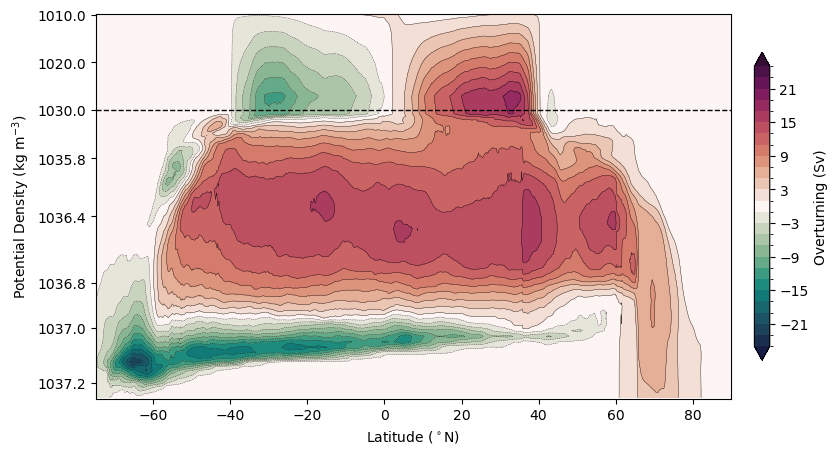

In [20]:
# Plot overturning with the stretched coordinate:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

max_psi = 25  # Sv
levels, cbarticks = levels_and_colorbarticks(max_psi)

psi_avg_plot.plot.contourf(
    ax=ax,
    levels=levels,
    cmap=cm.cm.curl,
    extend='both',
    cbar_kwargs={
        'shrink': 0.8,
        'label': 'Overturning (Sv)',
        'ticks': cbarticks,
        'pad': 0.03
    }
)

psi_avg_plot.plot.contour(
    ax=ax,
    levels=levels,
    colors='k',
    linewidths=0.25
)

yticks = np.array([
    1010, 1020, 1030, 1035.8, 1036.4, 1036.8, 1037.0, 1037.2
])

yticks_stretched = np.where(
    yticks <= rho_break,
    low_fraction * (yticks - rho_min) / (rho_break - rho_min),
    low_fraction + (1 - low_fraction) *
    ((yticks - rho_break) / (rho_max - rho_break))**dense_stretch
)

ax.set_yticks(yticks_stretched)
ax.set_yticklabels(yticks)
ax.set_ylim(1, 0)
ax.set_ylabel('Potential Density (kg m$^{-3}$)')
ax.set_xlabel('Latitude ($^\circ$N)')
ax.set_xlim([-75, 90])

# Draw a horizontal line where the stretching changes:
ax.axhline(low_fraction, color='k', linewidth=1.0, linestyle='--');

# Plotting in depth coordinates

Sometimes it's nice to see what this looks like in depth space, because it's a bit more intuitive. This requires remapping from density to depth space.

Unfortunately it seems not possible to do this density to depth conversion in the `MC_25km_jra_iaf+wombatlite-test3v2-00532b88` experiment, because the zonal average of `rhopot2` is non-monotonic nearly everywhere. If you want an example of this that works in MOM5, there is one here:
https://github.com/COSIMA/cosima-recipes/blob/v0.1.7/03-Advanced-Recipes/Overturning_Circulation.ipynb

# Atlantic and Indo-Pacific basin components of the Meridional Overturning Circulation

Here, we compute the zonally averaged meridional overturning streamfunction in density space in a similar fashion to the above, except that we partition the overturning circulation into the Atlantic and Indo-Pacific Basins. Strong North Atlantic deep water circulation in the Atlantic can sometimes obscure Antarctic Bottom Water circulation in the IndoPacific in global zonally-averaged calculations, something we can minimise by the masking procedure below.

Compute times were calculated using 28 cpus and 124 GB memory Jupyter Lab on gadi, using conda environment analysis3-25.06.

# Create Masks for the Atlantic and IndoPacific Basins

Here we want to create two masks; one that masks for the Southern Ocean south of 33$^\circ$S (around the bottom of Africa) and the Atlantic Ocean, and one that masks for the Southern Ocean south of 33$^\circ$S and the Indian plus Pacific Oceans.

A bit of fiddling is a little unavoidable here but the procedure below should be compatible with 0.25$^\circ$ or 1$^\circ$ grid data so you don't have to repeat the whole process.

To start with, load a single density layer of the overturning variable that we want to mask, because this is on the correct grid. We will make our mask from this.

In [21]:
vmo = OM3_datastore.search(variable="vmo", frequency="1mon", file_id=".*rho2_l.*")
vmo = vmo.to_dask(xarray_open_kwargs={"use_cftime": True}).isel(time=0).isel(rho2_l=0).vmo

Now, make a `land_mask`. This is just a dataarray with `1`'s where you have ocean and `0`'s where you have land. We are going to work with this mask to delineate the different ocean basins.

In [22]:
land_mask = ~vmo.isnull()

Now, let's draw in a set of meridians that lie within land masses separating the Atlantic basin from the Indo-Pacific basins, to show where our mask is going to go. We will also have a line to delineate the southern boundary.

Note that the problems with this mask are:
* It is not perfect at the Panama Canal; 
* The Great Australian Bight is not counted in the Southern Ocean; 
* The calculation is done on tracer points, but streamfunction is actually found on the northern edge of the tracer grid; and
* The masks are defined in terms of `xh` and `yq`, which, as we saw above, are not longitude and latitude north of 65°N. So we only plot the basin overturning south of 65°N. Extending it further north would need masks defined in terms of `geolon` and `geolat`, and `sectionate` sections that only cross the basin in question.

These are all pretty minor issues for a global quantity like the overturning, but users should feel free to improve this if they like.

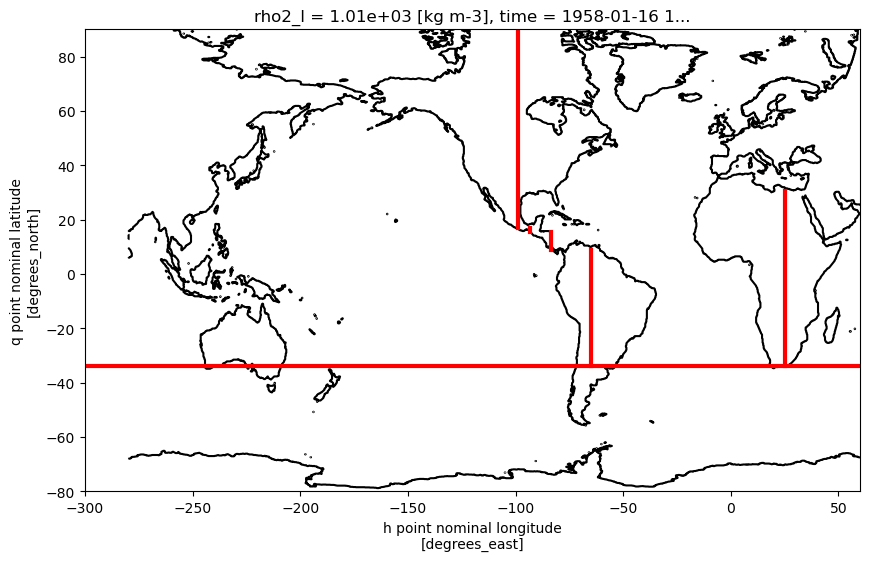

In [23]:
fig = plt.figure(2, (10, 6))
ax = plt.subplot()

land_mask.plot.contour(levels=[0.5], colors='k')

ax.plot([-300, 60], [-34,-34], 'r', linewidth = 3)
ax.plot([-65, -65], [-34, 9], 'r', linewidth = 3)
ax.plot([-83.7, -83.7], [9, 15.5], 'r', linewidth = 3)
ax.plot([-93.3, -93.3], [15.5, 17], 'r', linewidth = 3)
ax.plot([-99, -99], [17, 90], 'r', linewidth = 3)
ax.plot([25, 25], [-34,30.5], 'r', linewidth = 3)
ax.plot([79, 79], [30.5, 90], 'r', linewidth = 3)

ax.set_xlim([-300, 60])
ax.set_ylim([-80, 90]);

Now, let's make our masks along these dividing lines. Note that we include the Southern Ocean in both the Atlantic and the Indo-Pacific masks.

In [24]:
## create masks out of the above chunks
south_map = (land_mask.where(land_mask.yq < -34)).fillna(0)
indo_map1 = (land_mask.where(land_mask.yq < 9).where(land_mask.yq > -34).where(land_mask.xh > -280).where(land_mask.xh < -65)).fillna(0)
indo_map2 = (land_mask.where(land_mask.yq < 15).where(land_mask.yq > 9).where(land_mask.xh > -280).where(land_mask.xh < -83.7)).fillna(0)
indo_map3 = (land_mask.where(land_mask.yq < 17).where(land_mask.yq > 15).where(land_mask.xh > -280).where(land_mask.xh < -93.3)).fillna(0)
indo_map4 = (land_mask.where(land_mask.yq < 85).where(land_mask.yq > 17).where(land_mask.xh > -280).where(land_mask.xh < -99)).fillna(0)
indo_map5 = (land_mask.where(land_mask.yq < 30.5).where(land_mask.yq > -34).where(land_mask.xh > 25).where(land_mask.xh < 80)).fillna(0)

indo_sector_map = indo_map1 + indo_map2 + indo_map3 + indo_map4 + indo_map5 + south_map
indo_sector_mask = indo_sector_map.where(indo_sector_map>0)

atlantic_sector_map = (indo_sector_mask * 0).fillna(1) * land_mask
atlantic_sector_map = atlantic_sector_map + south_map
atlantic_sector_mask = atlantic_sector_map.where(atlantic_sector_map > 0)

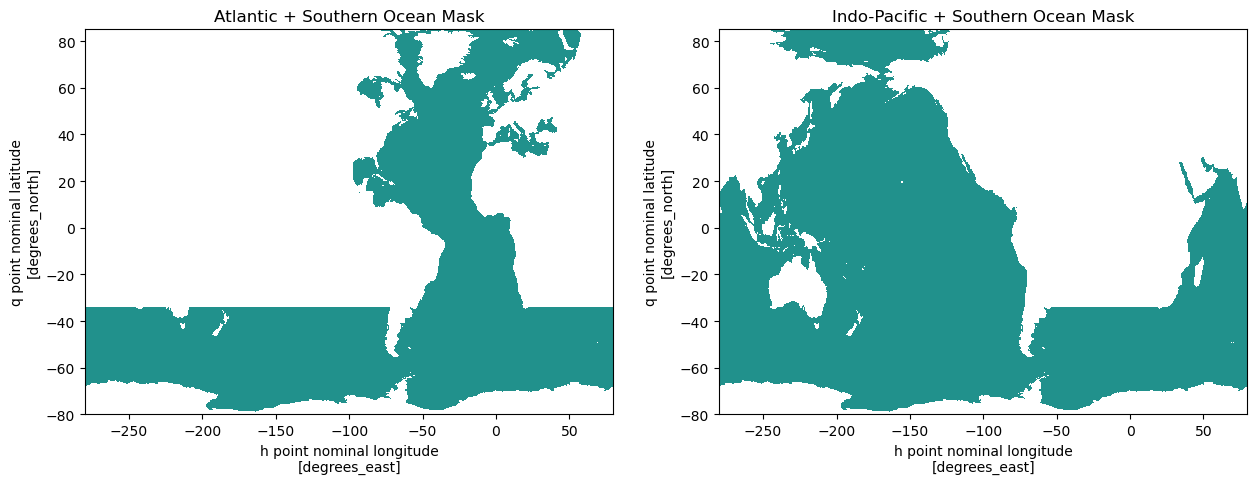

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

atlantic_sector_mask.plot(ax=ax[0], add_colorbar=False)
ax[0].set_ylim([-80, 85])
ax[0].set_title('Atlantic + Southern Ocean Mask')

indo_sector_mask.plot(ax=ax[1], add_colorbar=False)
ax[1].set_ylim([-80, 85])
ax[1].set_title('Indo-Pacific + Southern Ocean Mask');

# Mask `psi` by Basin and Compute Basin-Specific MOC

We use the `psi` from before, apply the mask and compute the basin-specific streamfunction in a similar manner as we did above.

In [26]:
# Atlantic-MOC
Atlantic_psi = (psi * atlantic_sector_mask).sum("xh")
Atlantic_psi = Atlantic_psi.cumsum("rho2_l") - Atlantic_psi.sum("rho2_l")
Atlantic_psi = Atlantic_psi.mean("time")
Atlantic_psi = Atlantic_psi.load()

# Indo-Pacific MOC
IndoPacific_psi = (psi * indo_sector_mask).sum("xh")
IndoPacific_psi = IndoPacific_psi.cumsum("rho2_l") - IndoPacific_psi.sum("rho2_l")
IndoPacific_psi = IndoPacific_psi.mean("time")
IndoPacific_psi = IndoPacific_psi.load()

# Plotting

Now plot the output.

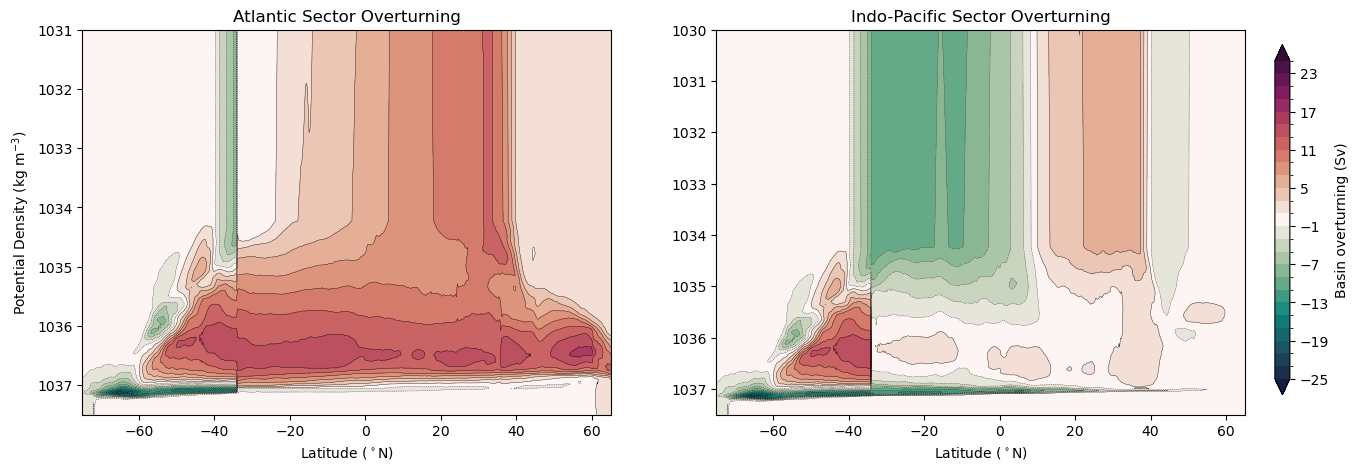

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Best if this is an odd number - otherwise levels and cbarticks may be mismatched:
max_psi = 25 # Sv

levels, cbarticks = levels_and_colorbarticks(max_psi)

# Atlantic MOC
Atlantic_psi.plot.contourf(ax=ax[0],
                           levels=levels,
                           cmap=cm.cm.curl,
                           extend='both',
                           add_colorbar=False)
Atlantic_psi.plot.contour(ax=ax[0],
                          levels=levels,
                          colors='k',
                          linewidths=0.25)
ax[0].invert_yaxis()
ax[0].set_ylim((1037.5, 1031))
ax[0].set_ylabel('Potential Density (kg m$^{-3}$)')
ax[0].set_xlabel('Latitude ($^\circ$N)')
ax[0].set_title('Atlantic Sector Overturning')

# Limit to 65ᵒN: north of that the basin masks and the sums along xh are not on true latitude (see above)
ax[0].set_xlim([-75, 65])


# Indo-Pacific MOC
h = IndoPacific_psi.plot.contourf(ax=ax[1],
                                  levels=levels,
                                  cmap=cm.cm.curl,
                                  extend='both',
                                  add_colorbar=False)
IndoPacific_psi.plot.contour(ax=ax[1],
                             levels=levels,
                             colors='k',
                             linewidths=0.25)
ax[1].invert_yaxis()
ax[1].set_ylim((1037.5, 1030))
ax[1].set_ylabel('')
ax[1].set_xlabel('Latitude ($^\circ$N)')
ax[1].set_title('Indo-Pacific Sector Overturning')

# Limit to 65ᵒN: north of that the basin masks and the sums along xh are not on true latitude (see above)
ax[1].set_xlim([-75, 65])

# Plot a colorbar
cax = plt.axes([0.92, 0.15, 0.01, 0.7])
cb = plt.colorbar(h, cax=cax, orientation='vertical')
cb.ax.set_ylabel('Basin overturning (Sv)');